# Handling Missing data


In [4]:
import pandas as pd 

data = {
    'Name' : ['Aryan', 'Kapil', 'Lalit', 'Inshan', 'Sagar'],
    'Age' : [23, None , 44, 23, None],
    'Salary' : [87000, 60000, 70000, None, None]
}
df = pd.DataFrame(data)
print("Original DataFrame",)
print( df)

print(df.isnull().sum())
df_drop = df.dropna()
print(df_drop)

df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Salary'].fillna(df['Salary'].mean(), inplace=True)
print(df)

Original DataFrame
     Name   Age   Salary
0   Aryan  23.0  87000.0
1   Kapil   NaN  60000.0
2   Lalit  44.0  70000.0
3  Inshan  23.0      NaN
4   Sagar   NaN      NaN
Name      0
Age       2
Salary    2
dtype: int64
    Name   Age   Salary
0  Aryan  23.0  87000.0
2  Lalit  44.0  70000.0
     Name   Age        Salary
0   Aryan  23.0  87000.000000
1   Kapil  30.0  60000.000000
2   Lalit  44.0  70000.000000
3  Inshan  23.0  72333.333333
4   Sagar  30.0  72333.333333


# Encoding Categorical value
* car Brand - BMW, Audi , Tesla
* Fule Type - Petrol, Diesel, CNG
Only for use Numbers

BMW-0
TEsla-1
Audi-2

or 
BMW-[0,1,2]
Tesla-[3,5,6]
# Label Encoding (replace numbers)
* Gender --> male - 0 , female - 1 
# One-Hot Encoding (Best)
* in this category, every category must become a new column.
  * Red(1,0,1)
  * blue(0,1,0)

In [5]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

df = pd.read_csv("sample_data.csv")

df_label = df.copy()

le = LabelEncoder()
df_label['Gender_Encoded'] = le.fit_transform(df_label['Gender'])
df_label['Passed_Encoded'] = le.fit_transform(df_label['Passed'])

""" print('\n Label Encoded Data')
print(df_label[['Name', 'Gender', 'Gender_Encoded', 'Passed', 'Passed_Encoded']]) """

df_encoded = pd.get_dummies(df_label, columns=['City'])
print('\nOne-Hot Encoded Data (City)')
print(df_encoded)



One-Hot Encoded Data (City)
      Name  Gender Passed  Gender_Encoded  Passed_Encoded  City_Bangalore  \
0     Aman    Male    Yes               1               1           False   
1    Priya  Female    Yes               0               1           False   
2    Rahul    Male     No               1               0            True   
3   Anjali  Female    Yes               0               1           False   
4     Ravi    Male    Yes               1               1           False   
5    Meera  Female     No               0               0           False   
6    Arjun    Male    Yes               1               1            True   
7     Neha  Female    Yes               0               1           False   
8    Imran    Male     No               1               0           False   
9    Sneha  Female    Yes               0               1           False   
10     Raj    Male    Yes               1               1           False   
11   Divya  Female     No               0      

# Feature Scaling (scale to 0-1) 
* these type of different features values converted into scale become same, then we can fairly compare it.
* Standard Scaler (Min-Max Scaling)
scaled = X - Xmin/Xmax - Xmin
* Standarize scaled = X - Mean/Standard Deviation (Best)

In [4]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd;

df_label = [[20,25,30]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_label)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_label)

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

data = {
    'StudyHours' : [1,2,3,4,5],
    'TestScore' : [40,50,60,70,80]
}

df = pd.DataFrame(data)

# StandardScaler
standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(df)

print("Standard Scaler Output:")
print(pd.DataFrame(standard_scaled, columns=['StudyHours', 'TestScore']))

#Min-Max Scaler
minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(df)

print("\nMinMax Scaled Output")
print(pd.DataFrame(minmax_scaled, columns=["StudyHours", "TestScore"]))

x = df[['StudyHours']]
y = df[['TestScore']]

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
print("training Data")
print(x_train)

print("Test Data")
print(x_test)

Standard Scaler Output:
   StudyHours  TestScore
0   -1.414214  -1.414214
1   -0.707107  -0.707107
2    0.000000   0.000000
3    0.707107   0.707107
4    1.414214   1.414214

MinMax Scaled Output
   StudyHours  TestScore
0        0.00       0.00
1        0.25       0.25
2        0.50       0.50
3        0.75       0.75
4        1.00       1.00
training Data
   StudyHours
4           5
2           3
0           1
3           4
Test Data
   StudyHours
1           2



# Supervised Machine Learning 
regression --> Linear Regression(Prediction Numbers using a straight line between a pt. to end pt.) [predict continous value]
* Its not about the line, its about story
* 5 rows use start
* accuracy is not always the Goal


In [5]:
from sklearn.linear_model import LinearRegression

X = [[1], [2], [3], [4], [5]]
y = [40, 50, 68, 100, 102]

model = LinearRegression()

model.fit(X, y) #Data Train

hours = float(input("Enter How many hours you studies = "))

predicted_marks = model.predict([[hours]]) #2D List

print(f"Based on your hours {hours}, you may score around {predicted_marks[0]:.2f} marks.")

Based on your hours 7.0, you may score around 141.60 marks.


# Classification
* Logistic regression (O/p value is 0 & 1)--> [No - 0 & 1 = Yes] 
* It is use the Sigmoid Function that is any number is covert between 0 and 1.
* Data is classify in different classes.
* Ex - spam/Not spam , pass/Fail, yes/No .

In [ ]:
from sklearn.linear_model import LogisticRegression

X = [[1], [2], [3], [4], [5]] #hour studied input
y = [0, 0, 1, 1, 1]       #result 0-Fail & 1-Pass

model = LogisticRegression()

model.fit(X, y)

hours = float(input("Enter How many hours you studies = "))

result = model.predict([[hours]])[0]

if result == 1:
    print(f"Based on your hours {hours}, you are likely to PASS.")
else:
    print(f"Based on your hours {hours}, you are likely to FAIL.")    

Based on your houurs 2.3, you are likely to FAIL.


* KNN(K Nearest Neighbour) (Must be use Odd value)
   * Choose K value
   * K closest input
   * How many each class
   * Support the better chance to win

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Data Weight and Size of apples and oranges.
X = [
    [180, 7],
    [200, 7.5],
    [250, 8],
    [300, 8.5],
    [330, 9],
    [360, 9.5]
]
#0 = Apple & 1 = Orange
y = [0, 0, 0, 1, 1, 1]

model = KNeighborsClassifier(n_neighbors = 3)
model.fit(X, y) #Model Train

weight = float(input("Enter the weight in grams"))
size = float(input("Enter the size in cm"))

prediction = model.predict([[weight, size]])[0]

if prediction == 0:
    print("This is likely an Apple")
else:
    print("This is likely an Orange")  

This is likely an Orange


* Decision Tree (asking Yes/No feature )



In [32]:
from sklearn.tree import DecisionTreeClassifier

#Size & Color shade(1-10)
X = [
    [7, 2],
    [8, 3],
    [9, 8],
    [10, 9]
]
#0 = Apple & 1 = Orange
y = [0, 0, 1, 1]

model = DecisionTreeClassifier()

model.fit(X, y) #Model Train

size = float(input("Enter the sizet in cm"))
shade = float(input("Enter the color shade (1-10) "))

prediction = model.predict([[size, shade]])[0]

if prediction == 0:
    print("This is likely an Apple")
else:
    print("This is likely an Orange")

This is likely an Apple


# Master Model Evalution
* Classification Matrics
  * accuracy (The % of total prediction of correct) Acc = correct_pred / total_pred
  * precision (How Often is correct)
  * Recall (Actual)
  * F1 score (95% fit imbalance)

In [2]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#True answers (What actually happened)
y_true = [1, 0, 1, 1, 0, 1, 0]

#Model's prediction (What it guessed)
y_pred = [1, 1, 1, 0, 0, 1, 1]

#evaluation
print("Accuracy: ", accuracy_score(y_true, y_pred))
print("Precision: ", precision_score(y_true, y_pred))
print("Recall: ", recall_score(y_true, y_pred))
print("F1 score: ", f1_score(y_true, y_pred))

Accuracy:  0.5714285714285714
Precision:  0.6
Recall:  0.75
F1 score:  0.6666666666666666


# Confusion Matrics (yes/No)
Based on 4 outcomes-
* TP (True Positive) machine-pass & Student-Pass [CG]
* TN (True Negative) M-fail & S-fail [CG]
* FP(false Positive) M-pass & s-fail [WG]
* FP(false Negative) M-fail & s-pass [WG]

In [5]:
from sklearn.metrics import confusion_matrix

y_true = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 1, 0]

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix")
print(cm)

Confusion Matrix
[[4 1]
 [1 4]]


* MAE (Mean Absolute Error)
  * take the mistake diff
  * remove the minus sign
  * add
  * divide
* MSE (Mean Squared Error)
  * Mistake sq. them
  * add
  * divide total
* RMSE (Root Mean Square Error)  
  


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

#real scores
real_score = [90, 60, 80, 100]

#Model guess
pred_scores = [85, 70, 70, 95]

mae = mean_absolute_error(real_score, pred_scores)

mse = mean_squared_error(real_score, pred_scores)

rmse = np.sqrt(mse)

print("MAE: On average off by: ", mae)
print("MSE: Square Mistake Value: ", mse)
print("RMAE: Final reaalistic error: ", rmse)

MAE: On average off by:  7.5
MSE: Square Mistake Value:  62.5
RMAE: Final reaalistic error:  7.905694150420948


# Project-1

In [6]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

data = pd.read_csv('student.csv')

X = data[['Hours']] #Double brackets = 2D input
y = data['Score'] # Target Column

model = LinearRegression()
model.fit(X, y)

pred_score = model.predict(X)

#evaluate
mae = mean_absolute_error(y, pred_score)
mse = mean_squared_error(y, pred_score)
rmse = np.sqrt(mse)

#show results
print("Mean Absolute ERROR (MAE): ", mae)
print("Mean Squared ERROR (MSE): ", mse)
print("Root Mean Squared ERROR (RMSE): ", rmse)

# new_hour = float(input("Enter a hours = "))
new_pred = model.predict([[9]])
print(f"Predicted Score for 9 hour = ", new_pred)

Mean Absolute ERROR (MAE):  0.6666666666666643
Mean Squared ERROR (MSE):  0.6285714285714282
Root Mean Squared ERROR (RMSE):  0.7928249671720916
Predicted Score for 9 hour =  [97.77142857]


C:\Users\Aryan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# 3-Step Formula
* X & Y numeric ? 
   * If YES then Scatter Plot for relationship
* Is one column a Category? 
   * Bar plot/Count plot
* Do you want to see a distribution shape? 
   * Histogram/KDE plot/Box plot

#  Advanced Project


Mean Absolute ERROR (MAE):  9.59
Mean Squared ERROR (MSE):  154.99
Root Mean Squared ERROR (RMSE):  12.45
R^2 Score (Model Accuracy):  0.3164


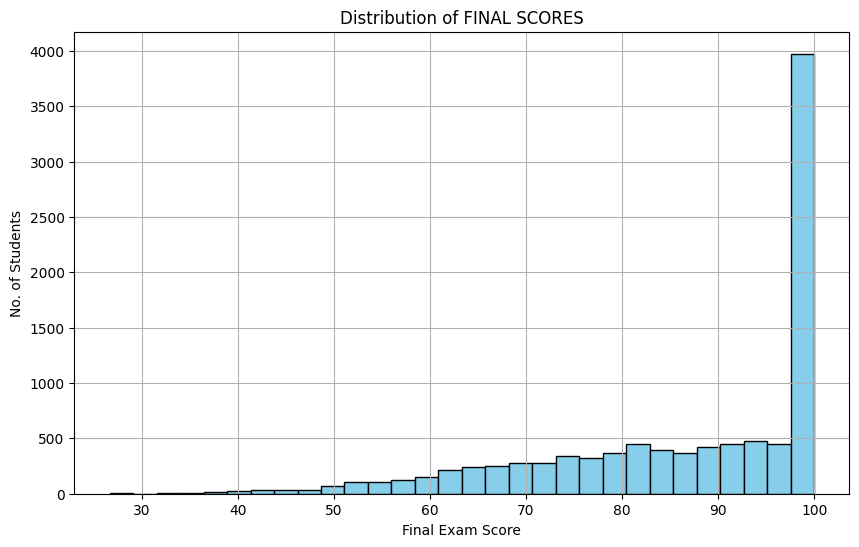

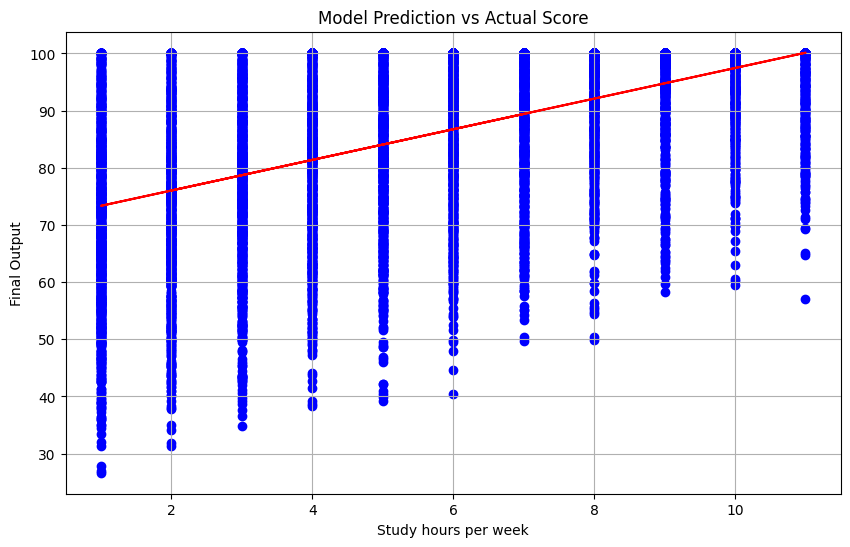

Predicted Final Score for 9 Hours is [94.76479421] score


C:\Users\Aryan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [7]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

#load dataset
data = pd.read_csv("student_dataset_10000_rows.csv")

#Input & Output
X = data[['study_hours']]
y = data['exam_score']

#train model

model = LinearRegression()
model.fit(X,y)
pred_score = model.predict(X)

#evaluate
mae = mean_absolute_error(y, pred_score)
mse = mean_squared_error(y, pred_score)
rmse = np.sqrt(mse)
r2 = r2_score(y, pred_score)

#show results
print("Mean Absolute ERROR (MAE): ", round(mae,2))
print("Mean Squared ERROR (MSE): ", round(mse, 2))
print("Root Mean Squared ERROR (RMSE): ", round(rmse, 2))
print("R^2 Score (Model Accuracy): ", round(r2, 4))

#histogram
plt.figure(figsize=(10, 6))
plt.hist(data["exam_score"], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of FINAL SCORES")
plt.xlabel("Final Exam Score")
plt.ylabel("No. of Students")
plt.grid(True)
plt.show()

#Scatter + regression Line
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label ='Actual Scores')
plt.plot(X, pred_score, color='red', label='Predicted Scores (Regression Line)')
plt.title("Model Prediction vs Actual Score")
plt.xlabel("Study hours per week")
plt.ylabel("Final Output")
plt.grid(True)
plt.show()

new_hours = 9
predicted_new_score = model.predict([[new_hours]])
print(f"Predicted Final Score for {new_hours} Hours is {predicted_new_score} score")

# UnSupervised Learning (No ans, No labels,raw data pattern learn)
* Clustering (same thing in a group) Do not predict value instead this is only for similar data points in a group
* Mean & Centroid (Median)
* Distance(Euclidean) d-sq. = (x2 - x1)sq. + (y2 - y1)sq.
* Variance = (x1 - mean)sq. + (x2 - mean)sq./n 
* Spread (High Difference)
* PCA (Take Important points)

# Unveiling data Insights
* K-Means Clustering (Ex. Mall huge data)
  * 5 steps
  1. Tell the machine k =3
  2. drop 3 random point 
  3. group leader
  4. center's of the group move
  5. repeat until unless
  * Elbo Method  

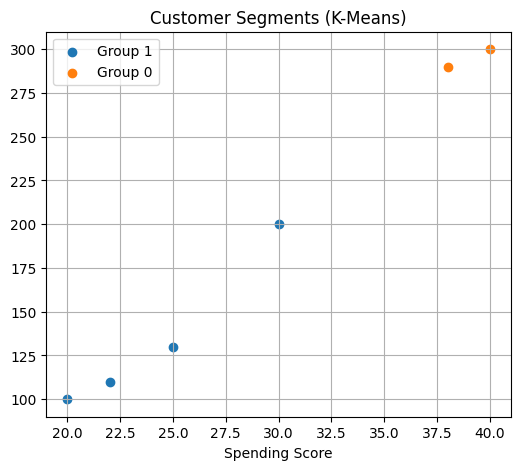

  Customer  Age  Spending  Group
0     Riya   20       100      1
1     Aman   30       200      1
2    Rahul   40       300      0
3     Neha   22       110      1
4    Imran   38       290      0
5    Sneha   25       130      1


In [1]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# sample data
data = {
    'Customer': ['Riya', 'Aman', 'Rahul', 'Neha', 'Imran', 'Sneha'],
    'Age': [20, 30, 40, 22, 38, 25],
    'Spending': [100, 200, 300, 110, 290, 130]
}

df = pd.DataFrame(data)

X = df[['Age', 'Spending']]

model = KMeans(n_clusters=2, random_state=42, n_init=10)

df['Group'] = model.fit_predict(X)

plt.figure(figsize=(6, 5))
for group in df['Group'].unique(): #[0,1]
    group_data = df[df['Group'] == group]
    plt.scatter(group_data['Age'], group_data['Spending'], label = f'Group {group}')

plt.xlabel('Spending Score')
plt.title('Customer Segments (K-Means)')
plt.legend()
plt.grid(True)
plt.show()

print(df)

* PCA (Principal Component Analysis)--> [features of data but do not need all data]
  * data huge then slower
  * visualise
  * overfitting
* Dimensionility reduction
  * columns rdeuce but meaning same
    

Variance captured by each PCA Component: 
[97.25  2.6 ]


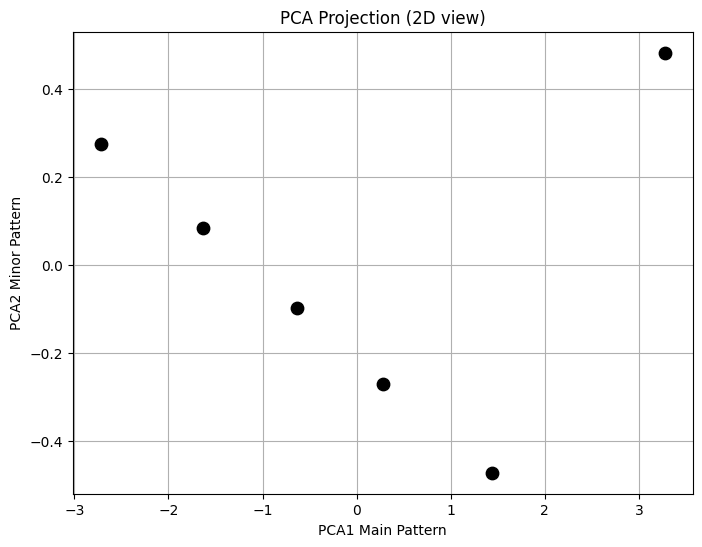

New data with 2 features PCA1 PCA2
       PCA1      PCA2
0 -2.717767  0.275864
1 -1.637626  0.083788
2 -0.638334 -0.098605
3  0.280111 -0.271316
4  1.441100 -0.473075
5  3.272517  0.483344
   Age  Income  Spending  Saving
0   25   30000        70    1000
1   30   40000        60    5000
2   35   50000        50    8000
3   40   60000        40   10000
4   45   70000        30   15000
5   70   80000        20   20000


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 

data = {
    'Age': [25, 30, 35, 40, 45, 70],
    'Income': [30000, 40000, 50000, 60000, 70000, 80000],
    'Spending': [70, 60, 50, 40, 30, 20],
    'Saving': [1000, 5000, 8000, 10000, 15000, 20000]
}

df = pd.DataFrame(data)

scaler = StandardScaler()

scaler = StandardScaler()
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(pca_result, columns=['PCA1', 'PCA2'])

explained_variance = pca.explained_variance_ratio_
print("Variance captured by each PCA Component: ")
print(np.round(explained_variance * 100, 2)) 

plt.figure(figsize=(8,6))
plt.scatter(pca_df['PCA1'], pca_df['PCA2'], color = 'black', s=80)
plt.title("PCA Projection (2D view)")
plt.xlabel('PCA1 Main Pattern')
plt.ylabel('PCA2 Minor Pattern')
plt.grid(True)
plt.show()

print("New data with 2 features PCA1 PCA2")
print(pca_df)
print(df)